# Tutorial nâng cao: MAS với Python và PyTorch

Nguyễn Nam Hải — B23DCCN277 — CT/04/hainn.

Notebook chạy trực tiếp ví dụ shopping, failure injection, classifier đã train, thống kê và kiểm thử. Toàn bộ 20 unit và năm exercise được giải thích trong PDF tutorial. Các bảng đọc từ kết quả thực thi đầy đủ đã lưu; các cell có công tắc RETRAIN/RERUN mặc định False để tránh âm thầm ghi đè artifact khi chỉ xem.

**Dữ liệu tổng hợp.** Không có API/LLM hoặc giao dịch thật. Chọn Restart Kernel and Run All để kiểm lại các cell dưới đây.

In [1]:
from pathlib import Path
import sys, json, csv, inspect, subprocess
import numpy as np
from IPython.display import display, Image, HTML
ROOT = Path.cwd()
if not (ROOT / 'tutorial').exists():
    ROOT = ROOT.parent
assert (ROOT / 'tutorial/mas_system.py').exists(), 'Open notebook from solution/'
sys.path[:0] = [str(ROOT / 'tutorial'), str(ROOT / 'assignment')]

def show_csv(path, limit=30):
    rows = list(csv.DictReader(path.open(encoding='utf-8')))
    import html
    if not rows: return
    columns = list(rows[0])
    head = '<tr>' + ''.join('<th>'+html.escape(c)+'</th>' for c in columns) + '</tr>'
    body = ''.join('<tr>'+''.join('<td>'+html.escape(str(r[c]))+'</td>' for c in columns)+'</tr>' for r in rows[:limit])
    display(HTML('<table>'+head+body+'</table>'))
    print(f'{path.name}: {len(rows)} rows; showing {min(limit,len(rows))}')
print('Working directory:', ROOT)


Working directory: /Users/handq2212/DaiHoc/Nam4/LTHTTM/agent-ai/ASIGNMENT-AGENT_02/solution


## 1. PEAS và trách nhiệm
Catalog truy hồi; recommender xếp hạng; policy kiểm budget/provenance; inventory kiểm kho; coordinator áp deadline và kiểm envelope. Hành động hệ là trả danh sách/trạng thái, không mua hàng.

In [2]:
from mas_system import *
for p in PRODUCTS:
    print(p)
print('Stock:', STOCK)

Product(id='p1', name='Lightweight laptop', category='electronics', price=850, tags=('portable', 'study'))
Product(id='p2', name='Wireless mouse', category='electronics', price=25, tags=('portable', 'accessory'))
Product(id='p3', name='Running shoes', category='sports', price=70, tags=('fitness', 'outdoor'))
Product(id='p4', name='Travel backpack', category='travel', price=55, tags=('portable', 'travel'))
Product(id='p5', name='Study tablet', category='electronics', price=150, tags=('study', 'portable'))
Stock: {'p1': 2, 'p2': 5, 'p3': 0, 'p4': 3, 'p5': 1}


## 2. Hợp đồng message
Sai task ID hoặc receiver không được dùng làm kết quả của yêu cầu hiện tại.

In [3]:
print(inspect.getsource(Message))
print(inspect.getsource(PolicyAgent))

@dataclass(frozen=True)
class Message:
    task_id: str
    sender: str
    receiver: str
    kind: str
    payload: dict[str,Any]
    def validate(self,receiver,kind):
        if not self.task_id or self.receiver!=receiver or self.kind!=kind or not isinstance(self.payload,dict):
            raise ValueError('Invalid message envelope')

class PolicyAgent:
    name='policy'
    async def handle(self,m):
        m.validate(self.name,'VALIDATE');lookup={p.id:p for p in PRODUCTS}
        ids=m.payload['ids'];allowed=set(m.payload['candidates']);budget=m.payload['budget']
        if any(i not in lookup or i not in allowed or lookup[i].price>budget for i in ids):
            raise ValueError('Candidate provenance/budget violation')
        return Message(m.task_id,self.name,m.sender,'VALIDATED',{'ids':ids})



## 3. Chạy luồng bình thường
Hai sản phẩm hợp lệ có ID p2 và p4. Laptop vượt budget; query trống không khớp toàn bộ.

In [4]:
system = Coordinator()
result = await system.shop('portable', 100, task_id='notebook-normal')
print(json.dumps(result, indent=2))
assert [p['id'] for p in result['items']] == ['p2', 'p4']
display(HTML('<pre>'+json.dumps(system.trace, indent=2)+'</pre>'))

{
  "status": "ok",
  "items": [
    {
      "id": "p2",
      "price": 25,
      "availability": "verified"
    },
    {
      "id": "p4",
      "price": 55,
      "availability": "verified"
    }
  ]
}


## 4. Budget, out of stock và đầu vào sai

In [5]:
for query,budget in [('portable',30),('sports',100),('',100),('unknown',100),('portable',-1),('portable',float('nan'))]:
    print(query,budget,await system.shop(query,budget))

portable 30 {'status': 'ok', 'items': [{'id': 'p2', 'price': 25, 'availability': 'verified'}]}
sports 100 {'status': 'no_results', 'items': []}
 100 {'status': 'no_results', 'items': []}
unknown 100 {'status': 'no_results', 'items': []}
portable -1 {'status': 'invalid_input', 'items': []}
portable nan {'status': 'invalid_input', 'items': []}


## 5. Bốn lỗi bắt buộc và một output giả
Timeout dùng wait_for thật; dữ liệu kho cũ trả availability_unverified. Forged ID bị chặn trước khi kết luận availability.

In [6]:
for scenario in ['timeout','malformed','stale','forged']:
    print(scenario,await system.shop('portable',100,scenario,task_id='notebook-'+scenario))

timeout {'status': 'timeout', 'items': []}
malformed {'status': 'contract_error', 'items': []}
stale {'status': 'availability_unverified', 'items': []}
forged {'status': 'contract_error', 'items': []}


## 6. Ablation: bỏ kiểm chứng
Quan sát sự khác biệt giữa nhiều thành viên và validation có hiệu lực.

In [7]:
unsafe = Coordinator(validate=False)
for scenario in ['stale','forged']:
    print(scenario,await unsafe.shop('portable',100,scenario))

stale {'status': 'ok', 'items': [{'id': 'p2', 'price': 25, 'availability': 'verified'}, {'id': 'p4', 'price': 55, 'availability': 'verified'}]}
forged {'status': 'ok', 'items': [{'id': 'p99', 'price': 0, 'availability': 'verified'}, {'id': 'p1', 'price': 850, 'availability': 'verified'}, {'id': 'p2', 'price': 25, 'availability': 'verified'}, {'id': 'p4', 'price': 55, 'availability': 'verified'}]}


## 7. Baseline đơn có cùng điều kiện đúng
Các đường bình thường cần tương đương. Baseline timeout được tiêm đồng bộ, không dùng để so trực tiếp thời gian chờ deadline với MAS.

In [8]:
for q in ['portable','study','sports','unknown','']:
    for b in [0,30,100,1000]:
        assert single_pipeline(q,b) == await system.shop(q,b)
print('20 normal input combinations matched')

20 normal input combinations matched


## 8. Dữ liệu intent và chia theo nhóm
432 câu tổng hợp; vocabulary chỉ xây trên train. Đối tượng được chia sẻ giữa split, nên bài test vẫn dễ hơn ngôn ngữ thật.

In [9]:
from train_intent import dataset, Router, run as train_intent
rows=dataset()
from collections import Counter
print(Counter(r['split'] for r in rows))
for split in ['train','validation','test']:
    print(split,next(r for r in rows if r['split']==split))
RETRAIN=False
if RETRAIN:
    train_intent(ROOT/'results/tutorial')
else:
    print('Reading the supplied trained checkpoint and measured artifacts')

Counter({'train': 270, 'test': 108, 'validation': 54})
train {'text': 'tìm mua laptop cho tôi', 'label': 0, 'class': 'ecommerce', 'group': '0:0', 'split': 'train'}
validation {'text': 'đề xuất mua laptop cho tôi', 'label': 0, 'class': 'ecommerce', 'group': '0:5', 'split': 'validation'}
test {'text': 'giúp chọn laptop cho tôi', 'label': 0, 'class': 'ecommerce', 'group': '0:6', 'split': 'test'}
Reading the supplied trained checkpoint and measured artifacts


## 9. Kiến trúc và huấn luyện
Loss nhận logits. Validation dùng chọn epoch và threshold; test giữ cho báo cáo cuối.

In [10]:
from train_intent import IntentNet
print(inspect.getsource(IntentNet))
metrics=json.loads((ROOT/'results/tutorial/intent_metrics.json').read_text())
print(json.dumps(metrics,ensure_ascii=False,indent=2))

class IntentNet(nn.Module):
    def __init__(self,n):super().__init__();self.net=nn.Sequential(nn.Linear(n,32),nn.ReLU(),nn.Linear(32,3))
    def forward(self,x):return self.net(x)

{
  "accuracy": 1.0,
  "macro_f1": 1.0,
  "precision": [
    1.0,
    1.0,
    1.0
  ],
  "recall": [
    1.0,
    1.0,
    1.0
  ],
  "f1": [
    1.0,
    1.0,
    1.0
  ],
  "confusion_matrix": [
    [
      36,
      0,
      0
    ],
    [
      0,
      36,
      0
    ],
    [
      0,
      0,
      36
    ]
  ],
  "splits": {
    "train": 270,
    "validation": 54,
    "test": 108
  },
  "threshold": 0.5,
  "selected_epoch": 120,
  "test_coverage": 1.0,
  "selective_accuracy": 1.0,
  "vocabulary_size": 79,
  "seed": 42,
  "torch": "2.8.0",
  "limitation": "Synthetic template dataset; group split by verb family, objects shared. Not evidence of real-world NLU.",
  "ood": [
    {
      "text": "xin chào",
      "intent": "clarify",
      "confidence": 0.49433353543281555
    },
    {
      "text": "thờ

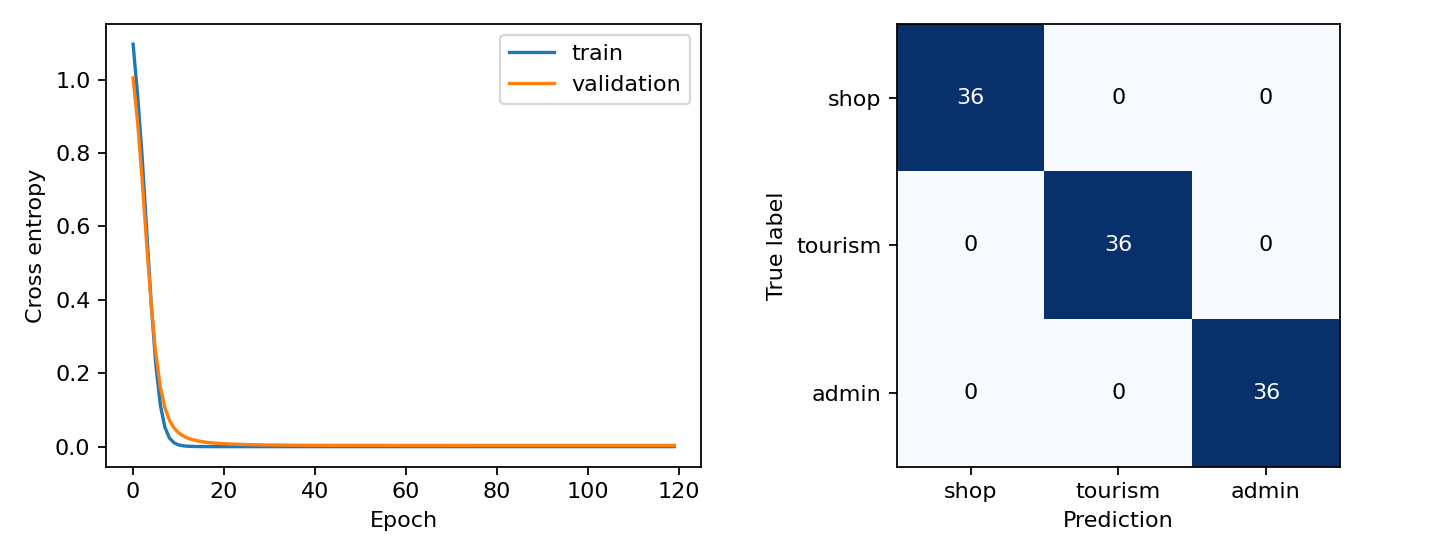

In [11]:
display(Image(filename=str(ROOT/'results/tutorial/intent_training.png')))

## 10. Định tuyến và abstention
Độ tự tin cao không bảo đảm thuộc miền. Giữ nguyên các lỗi OOD để nhìn giới hạn.

In [12]:
router=Router(ROOT/'results/tutorial')
for text in ['tìm mua laptop cho tôi','gợi ý tham quan bảo tàng','hướng dẫn đặt hẹn giấy tờ bảo hiểm','xin chào','thời tiết hôm nay thế nào','giải phương trình']:
    print(text,'->',router.route(text))

tìm mua laptop cho tôi -> {'intent': 'ecommerce', 'confidence': 0.9999960660934448}
gợi ý tham quan bảo tàng -> {'intent': 'tourism', 'confidence': 0.9999511241912842}
hướng dẫn đặt hẹn giấy tờ bảo hiểm -> {'intent': 'healthcare_admin', 'confidence': 0.9999740123748779}
xin chào -> {'intent': 'clarify', 'confidence': 0.49433353543281555}
thời tiết hôm nay thế nào -> {'intent': 'ecommerce', 'confidence': 0.9876664876937866}
giải phương trình -> {'intent': 'tourism', 'confidence': 0.9311287999153137}


## 11. Benchmark B0–B3
11 ca × 20 repetition mỗi kiến trúc. Success kiểm cả status và ID. B2 dùng câu shopping cố định để đo overhead, không đo routing đa miền.

In [13]:
show_csv(ROOT/'results/tutorial/mas_benchmark.csv')
RERUN_BENCHMARK=False
if RERUN_BENCHMARK:
    from evaluate_mas import run as benchmark
    await benchmark(ROOT/'results/tutorial')

mas_benchmark.csv: 4 rows; showing 4


system,requests,success_rate,p50_ms,p95_ms,messages_mean,violation_rate
B0_single,220,1.0,0.00483299999998188,0.00901009999999534,0.0,0.0
B1_rule_MAS,220,1.0,0.24056249999993007,11.097260750000004,6.0,0.0
B2_learned_MAS,220,1.0,0.3103540000000127,11.402941349999862,6.0,0.0
B3_no_validation,220,0.7272727272727273,0.21720850000006564,11.304238150000012,4.7272727272727275,0.18181818181818182


## 12. Chạy bộ kiểm thử thực tế

In [14]:
completed=subprocess.run([sys.executable,'-m','unittest','discover','-s',str(ROOT/'tutorial'),'-p','test_*.py'],cwd=ROOT,capture_output=True,text=True)
print(completed.stdout+completed.stderr)
assert completed.returncode==0

.................
----------------------------------------------------------------------
Ran 17 tests in 0.111s

OK



## 13. Kết luận thực hành
B0/B1 cùng thành công trên bộ ca toy; MAS có thêm overhead. Validation có ích trong các ca lỗi. Classifier train thật đạt 100% test tổng hợp nhưng có OOD false acceptance. Năm exercise có đủ PEAS, code, model, failure injection, benchmark và demo; xem PDF để đọc toàn bộ giải thích và giới hạn.